# 11 — Compression of the context-loss curve

This notebook tests whether the attribution-relevant information in the sampled context-loss curve

\[
(L_8,L_{32},L_{128},L_{256})
\]

can be compressed to one or two coordinates with negligible loss of predictive performance.

The main candidate representations are:

\[
L_8,
\]

\[
L_{256},
\]

\[
(L_8,L_{256}),
\]

and

\[
(L_8,L_{32},L_{128},L_{256}).
\]

Because

\[
U(256)=L_8-L_{256},
\]

the pair \((L_8,L_{256})\) is information-equivalent to \((L_8,U(256))\).

The scientific question is not whether the intermediate losses are mathematically reconstructible. They are not. It is whether they contribute **meaningful generator-attribution information** beyond the compressed endpoint representation.


## Interpretation target

There are three interesting outcomes.

### Outcome A — one-number compression

If

\[
L_{256}
\approx
(L_8,L_{256})
\approx
(L_8,L_{32},L_{128},L_{256}),
\]

then the attribution-relevant information in the sampled curve is almost entirely concentrated in one long-context loss value.

### Outcome B — two-number compression

If

\[
(L_8,L_{256})
>
L_{256}
\]

but

\[
(L_8,L_{32},L_{128},L_{256})
\approx
(L_8,L_{256}),
\]

then source information is largely captured by two interpretable coordinates:

- short-context predictive difficulty \(L_8\);
- total contextual gain \(L_8-L_{256}\).

### Outcome C — the full curve matters

If the full curve consistently outperforms the endpoint pair, then intermediate context scales retain distinct source information and the compression hypothesis fails.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
)

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"

assert RAW_PATH.exists(), RAW_PATH
assert CTX_PATH.exists(), CTX_PATH

raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()

print("raw:", raw.shape)
print("context:", ctx.shape)


raw: (9000, 10)
context: (9000, 8)


## Build the matched GPT/Claude pool

Use the large existing Ghostbuster detector pool rather than the small topology pilot. This gives the compression test substantially more power.

All GPT/Claude documents corresponding to the same `(domain, group_id)` source are kept together in train/test splits.


In [2]:
machine = raw[raw["generator"].isin(["gpt", "claude"])].copy()
machine["pair_id"] = (
    machine["domain"].astype(str)
    + "::"
    + machine["group_id"].astype(str)
)

LOSS_COLS = [
    "context_loss_8",
    "context_loss_32",
    "context_loss_128",
    "context_loss_256",
]

work = machine[
    ["row_id", "pair_id", "domain", "group_id", "generator"]
].merge(
    ctx[
        ["row_id", *LOSS_COLS]
    ],
    on="row_id",
    how="inner",
    validate="one_to_one",
)

# Require every document to have the complete 4-point context-loss curve
work = work.dropna(subset=LOSS_COLS).copy()

# NOW determine complete matched GPT/Claude source pairs.
# This is important: a pair is usable only if both generator documents
# survive the complete-curve requirement.
complete = (
    work.groupby("pair_id")["generator"]
    .agg(["size", "nunique"])
    .query("size == 2 and nunique == 2")
    .index
)

work = work[work["pair_id"].isin(complete)].copy()

work["label"] = (work["generator"] == "claude").astype(int)

print("complete matched source pairs:", work["pair_id"].nunique())
print("documents:", len(work))
print("\nMissing values remaining:")
display(work[LOSS_COLS].isna().sum())

display(work.groupby(["domain", "generator"]).size())

complete matched source pairs: 2860
documents: 5720

Missing values remaining:


context_loss_8      0
context_loss_32     0
context_loss_128    0
context_loss_256    0
dtype: int64

domain  generator
essay   claude       1000
        gpt          1000
reuter  claude        982
        gpt           982
wp      claude        878
        gpt           878
dtype: int64

## Feature representations


In [3]:
FEATURE_SETS = {
    "L8": ["context_loss_8"],
    "L32": ["context_loss_32"],
    "L128": ["context_loss_128"],
    "L256": ["context_loss_256"],
    "L8+L256": ["context_loss_8", "context_loss_256"],
    "FullCurve": [
        "context_loss_8",
        "context_loss_32",
        "context_loss_128",
        "context_loss_256",
    ],
}

for name, cols in FEATURE_SETS.items():
    print(name, "->", cols)


L8 -> ['context_loss_8']
L32 -> ['context_loss_32']
L128 -> ['context_loss_128']
L256 -> ['context_loss_256']
L8+L256 -> ['context_loss_8', 'context_loss_256']
FullCurve -> ['context_loss_8', 'context_loss_32', 'context_loss_128', 'context_loss_256']


# Part I — Source-group-held-out compression test

Run 20 matched 80/20 source-pair splits.

The headline comparisons are:

\[
(L_8,L_{256}) - L_{256}
\]

and

\[
\text{FullCurve} - (L_8,L_{256}).
\]

The first measures the value of retaining the short-context endpoint.

The second measures the value lost by compressing the four-point curve to two endpoints.


In [4]:
def make_clf(C_reg=1.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=4000,
            random_state=0,
            C=C_reg,
        )),
    ])

pair_ids = np.array(sorted(work["pair_id"].unique()))
rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(pair_ids))
    cut = int(.8 * len(pair_ids))

    tr_ids = set(pair_ids[perm[:cut]])
    te_ids = set(pair_ids[perm[cut:]])

    tr = work[work["pair_id"].isin(tr_ids)]
    te = work[work["pair_id"].isin(te_ids)]

    assert set(tr["pair_id"]).isdisjoint(set(te["pair_id"]))

    for method, cols in FEATURE_SETS.items():
        model = make_clf(C_reg=1.0)
        model.fit(tr[cols], tr["label"])

        prob = model.predict_proba(te[cols])[:, 1]
        pred = (prob >= .5).astype(int)
        y = te["label"].to_numpy()

        rows.append({
            "seed": seed,
            "method": method,
            "auroc": roc_auc_score(y, prob),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred),
            "f1": f1_score(y, pred),
        })

split_results = pd.DataFrame(rows)

display(
    split_results.groupby("method")[
        ["auroc", "balanced_accuracy", "accuracy", "f1"]
    ]
    .mean()
    .sort_values("auroc", ascending=False)
)

split_results.to_csv(
    RESULTS / "context_curve_compression_splits.csv",
    index=False,
)


,auroc,balanced_accuracy,accuracy,f1
method,,,,
FullCurve,0.710024,0.643925,0.643925,0.631397
L8+L256,0.708991,0.643619,0.643619,0.631463
L256,0.708668,0.642526,0.642526,0.629809
L128,0.704755,0.644668,0.644668,0.633203
L32,0.667158,0.615035,0.615035,0.605341
L8,0.632981,0.597990,0.597990,0.588321


In [5]:
def summarize_delta(df, a, b, metric):
    wide = df.pivot(index="seed", columns="method", values=metric)
    vals = (wide[a] - wide[b]).to_numpy()

    return {
        "comparison": f"{a} vs {b}",
        "metric": metric,
        "mean_delta": vals.mean(),
        "median_delta": np.median(vals),
        "q25": np.quantile(vals, .25),
        "q75": np.quantile(vals, .75),
        "min": vals.min(),
        "max": vals.max(),
        "positive": int((vals > 0).sum()),
        "nonnegative": int((vals >= 0).sum()),
        "n": len(vals),
    }

comparisons = [
    ("L8+L256", "L256"),
    ("FullCurve", "L8+L256"),
    ("FullCurve", "L256"),
    ("L256", "L128"),
    ("L128", "L32"),
    ("L32", "L8"),
]

rows = []
for a, b in comparisons:
    for metric in ["auroc", "balanced_accuracy", "f1"]:
        rows.append(summarize_delta(split_results, a, b, metric))

summary = pd.DataFrame(rows)
display(summary)

summary.to_csv(
    RESULTS / "context_curve_compression_summary.csv",
    index=False,
)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,nonnegative,n
0,L8+L256 vs L256,auroc,0.000322,0.000659,-0.000242,0.000888,-0.001525,0.001323,14,14,20
1,L8+L256 vs L256,balanced_accuracy,0.001093,0.000874,-0.000874,0.002622,-0.002622,0.006119,10,12,20
2,L8+L256 vs L256,f1,0.001654,0.001531,-0.000811,0.004341,-0.003919,0.008079,13,13,20
3,FullCurve vs L8+L256,auroc,0.001033,0.000990,-0.000228,0.002590,-0.004059,0.004187,14,14,20
4,FullCurve vs L8+L256,balanced_accuracy,0.000306,0.000437,-0.003059,0.003934,-0.011364,0.008741,11,12,20
5,FullCurve vs L8+L256,f1,-0.000066,-0.000275,-0.005145,0.005838,-0.012150,0.010189,10,10,20
6,FullCurve vs L256,auroc,0.001356,0.001693,-0.000111,0.002654,-0.003194,0.005098,15,15,20
7,FullCurve vs L256,balanced_accuracy,0.001399,0.002622,-0.003059,0.005026,-0.008741,0.012238,13,13,20
8,FullCurve vs L256,f1,0.001588,0.002777,-0.003294,0.006120,-0.011123,0.013269,12,12,20
9,L256 vs L128,auroc,0.003914,0.004259,0.000355,0.005852,-0.001800,0.010945,17,17,20


# Part II — Retained-performance ratios

For a compression claim, absolute deltas are useful but retained performance is also intuitive.

Define, relative to a simple chance baseline of 0.5 AUROC,

\[
R_{\rm retained}(A\leftarrow F)
=
\frac{\mathrm{AUROC}(A)-0.5}
{\mathrm{AUROC}(F)-0.5},
\]

where \(F\) is the full curve and \(A\) is the compressed representation.

A value near 1 means the compressed representation retains nearly all of the full curve's above-chance attribution performance.

This is descriptive and should not be interpreted as a universal information-theoretic percentage.


In [6]:
mean_perf = (
    split_results.groupby("method")[["auroc", "balanced_accuracy", "f1"]]
    .mean()
)

full_auc = mean_perf.loc["FullCurve", "auroc"]

retention_rows = []

for method in ["L8", "L32", "L128", "L256", "L8+L256"]:
    auc = mean_perf.loc[method, "auroc"]

    retention_rows.append({
        "method": method,
        "mean_auroc": auc,
        "absolute_gap_to_full": full_auc - auc,
        "above_chance_retained_fraction": (
            (auc - 0.5) / (full_auc - 0.5)
            if full_auc > 0.5 else np.nan
        ),
    })

retention = pd.DataFrame(retention_rows)
display(retention)

retention.to_csv(
    RESULTS / "context_curve_compression_retention.csv",
    index=False,
)


,method,mean_auroc,absolute_gap_to_full,above_chance_retained_fraction
0,L8,0.632981,0.077043,0.633171
1,L32,0.667158,0.042866,0.795898
2,L128,0.704755,0.005269,0.974912
3,L256,0.708668,0.001356,0.993546
4,L8+L256,0.708991,0.001033,0.995081


# Part III — Held-out-domain compression

Train on two domains and test on the third.

The key question is whether endpoint compression remains adequate under domain transfer.


In [7]:
LABELS = {
    "essay": "Essay",
    "reuter": "Reuters",
    "wp": "Wikipedia",
}

transfer_rows = []

for heldout in ["essay", "reuter", "wp"]:
    tr = work[work["domain"] != heldout]
    te = work[work["domain"] == heldout]

    for method, cols in FEATURE_SETS.items():
        model = make_clf(C_reg=1.0)
        model.fit(tr[cols], tr["label"])

        prob = model.predict_proba(te[cols])[:, 1]
        pred = (prob >= .5).astype(int)
        y = te["label"].to_numpy()

        transfer_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": LABELS[heldout],
            "method": method,
            "auroc": roc_auc_score(y, prob),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "f1": f1_score(y, pred),
        })

transfer = pd.DataFrame(transfer_rows)

display(
    transfer.pivot(
        index="heldout_domain_label",
        columns="method",
        values="auroc",
    )
)

transfer.to_csv(
    RESULTS / "context_curve_compression_cross_domain.csv",
    index=False,
)


method,FullCurve,L128,L256,L32,L8,L8+L256
heldout_domain_label,,,,,,
Essay,0.748551,0.745380,0.749891,0.690457,0.665723,0.749612
Reuters,0.751814,0.744866,0.754617,0.701674,0.654940,0.755208
Wikipedia,0.642143,0.643779,0.639750,0.622672,0.590915,0.640641


In [8]:
transfer_delta_rows = []

for heldout in ["essay", "reuter", "wp"]:
    sub = transfer[transfer["heldout_domain"] == heldout].set_index("method")

    for a, b in [
        ("L8+L256", "L256"),
        ("FullCurve", "L8+L256"),
    ]:
        transfer_delta_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": LABELS[heldout],
            "comparison": f"{a} vs {b}",
            "delta_auroc": sub.loc[a, "auroc"] - sub.loc[b, "auroc"],
            "delta_balanced_accuracy": (
                sub.loc[a, "balanced_accuracy"]
                - sub.loc[b, "balanced_accuracy"]
            ),
            "delta_f1": sub.loc[a, "f1"] - sub.loc[b, "f1"],
        })

transfer_deltas = pd.DataFrame(transfer_delta_rows)
display(transfer_deltas)

transfer_deltas.to_csv(
    RESULTS / "context_curve_compression_cross_domain_deltas.csv",
    index=False,
)


,heldout_domain,heldout_domain_label,comparison,delta_auroc,delta_balanced_accuracy,delta_f1
0,essay,Essay,L8+L256 vs L256,-0.000279,-0.005000,-0.005009
1,essay,Essay,FullCurve vs L8+L256,-0.001061,0.000000,0.000000
2,reuter,Reuters,L8+L256 vs L256,0.000591,0.001527,0.000286
3,reuter,Reuters,FullCurve vs L8+L256,-0.003394,-0.001018,0.001655
4,wp,Wikipedia,L8+L256 vs L256,0.000891,0.007973,0.006799
5,wp,Wikipedia,FullCurve vs L8+L256,0.001502,-0.005125,-0.005906


# Part IV — Regularization sensitivity

Because the full curve has more correlated features than the endpoint representations, repeat the key comparisons across a small regularization grid.


In [9]:
REG_GRID = [0.01, 0.1, 1.0, 10.0]
reg_rows = []

for C_reg in REG_GRID:
    for seed in range(20):
        rng = np.random.RandomState(seed)
        perm = rng.permutation(len(pair_ids))
        cut = int(.8 * len(pair_ids))

        tr_ids = set(pair_ids[perm[:cut]])
        te_ids = set(pair_ids[perm[cut:]])

        tr = work[work["pair_id"].isin(tr_ids)]
        te = work[work["pair_id"].isin(te_ids)]

        for method in ["L256", "L8+L256", "FullCurve"]:
            cols = FEATURE_SETS[method]

            model = make_clf(C_reg=C_reg)
            model.fit(tr[cols], tr["label"])

            prob = model.predict_proba(te[cols])[:, 1]
            y = te["label"].to_numpy()

            reg_rows.append({
                "C_reg": C_reg,
                "seed": seed,
                "method": method,
                "auroc": roc_auc_score(y, prob),
            })

reg = pd.DataFrame(reg_rows)

reg_summary = []

for C_reg in REG_GRID:
    sub = reg[reg["C_reg"] == C_reg]
    wide = sub.pivot(index="seed", columns="method", values="auroc")

    for a, b in [
        ("L8+L256", "L256"),
        ("FullCurve", "L8+L256"),
    ]:
        d = wide[a] - wide[b]

        reg_summary.append({
            "C_reg": C_reg,
            "comparison": f"{a} vs {b}",
            "mean_delta_auroc": d.mean(),
            "median_delta_auroc": d.median(),
            "q25": d.quantile(.25),
            "q75": d.quantile(.75),
            "positive": int((d > 0).sum()),
            "n": len(d),
        })

reg_summary = pd.DataFrame(reg_summary)
display(reg_summary)

reg_summary.to_csv(
    RESULTS / "context_curve_compression_regularization.csv",
    index=False,
)


,C_reg,comparison,mean_delta_auroc,median_delta_auroc,q25,q75,positive,n
0,0.01,L8+L256 vs L256,-0.000996,-0.000651,-0.001719,-0.000174,1,20
1,0.01,FullCurve vs L8+L256,0.001876,0.001728,0.001054,0.002932,18,20
2,0.10,L8+L256 vs L256,0.000274,0.000535,-0.000023,0.000685,14,20
3,0.10,FullCurve vs L8+L256,0.001166,0.001142,-0.000188,0.002567,14,20
4,1.00,L8+L256 vs L256,0.000322,0.000659,-0.000242,0.000888,14,20
5,1.00,FullCurve vs L8+L256,0.001033,0.000990,-0.000228,0.002590,14,20
6,10.00,L8+L256 vs L256,0.000344,0.000700,-0.000238,0.000952,14,20
7,10.00,FullCurve vs L8+L256,0.001005,0.001006,-0.000232,0.002599,14,20


# Part V — Visualization


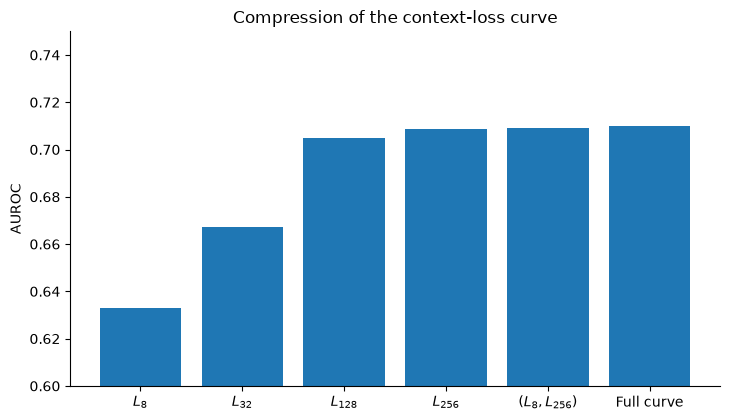

In [12]:
means = split_results.groupby("method")["auroc"].mean()

order = ["L8", "L32", "L128", "L256", "L8+L256", "FullCurve"]

fig, ax = plt.subplots(figsize=(7.4, 4.3))
x = np.arange(len(order))
ax.bar(x, [means[m] for m in order])

ax.set_xticks(x)
ax.set_xticklabels([
    r"$L_8$",
    r"$L_{32}$",
    r"$L_{128}$",
    r"$L_{256}$",
    r"$(L_8,L_{256})$",
    "Full curve",
])
ax.set_ylabel("AUROC")
ax.set_title("Compression of the context-loss curve")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.ylim(0.6, 0.75)
fig.tight_layout()

fig.savefig(
    FIGURES / "context_curve_compression.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "context_curve_compression.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


## Interpretation

The most attractive compression result would be:

\[
\text{FullCurve}
\approx
(L_8,L_{256})
\]

with a very small split-level AUROC difference, while

\[
(L_8,L_{256})
>
L_{256}.
\]

That would support a two-coordinate interpretation:

- \(L_8\): short-context predictive difficulty
- \(L_8-L_{256}\): total long-context predictive benefit

If even \(L_{256}\) alone matches the endpoint pair and full curve, then the attribution-relevant curve is effectively one-dimensional for this task.

Any compression claim must remain task- and scorer-specific. This notebook does not establish that intermediate context scales are universally uninformative for explanation, intervention analysis, or other datasets.


In [11]:
def fs(x):
    return f"{x:+.6f}"

print("MEAN AUROC")
display(
    split_results.groupby("method")["auroc"]
    .mean()
    .sort_values(ascending=False)
)

print("\nKEY COMPRESSION DELTAS")

for a, b in [
    ("L8+L256", "L256"),
    ("FullCurve", "L8+L256"),
]:
    r = summary[
        (summary["comparison"] == f"{a} vs {b}")
        & (summary["metric"] == "auroc")
    ].iloc[0]

    print(
        f"{a} - {b}",
        "| mean", fs(r.mean_delta),
        "| median", fs(r.median_delta),
        "| IQR", f"[{fs(r.q25)}, {fs(r.q75)}]",
        "| positive", f"{int(r.positive)}/{int(r.n)}",
    )

print("\nRETAINED PERFORMANCE")
display(retention)

print("\nHELD-OUT DOMAIN")
display(transfer_deltas)


MEAN AUROC


method
FullCurve    0.710024
L8+L256      0.708991
L256         0.708668
L128         0.704755
L32          0.667158
L8           0.632981
Name: auroc, dtype: float64


KEY COMPRESSION DELTAS
L8+L256 - L256 | mean +0.000322 | median +0.000659 | IQR [-0.000242, +0.000888] | positive 14/20
FullCurve - L8+L256 | mean +0.001033 | median +0.000990 | IQR [-0.000228, +0.002590] | positive 14/20

RETAINED PERFORMANCE


,method,mean_auroc,absolute_gap_to_full,above_chance_retained_fraction
0,L8,0.632981,0.077043,0.633171
1,L32,0.667158,0.042866,0.795898
2,L128,0.704755,0.005269,0.974912
3,L256,0.708668,0.001356,0.993546
4,L8+L256,0.708991,0.001033,0.995081



HELD-OUT DOMAIN


,heldout_domain,heldout_domain_label,comparison,delta_auroc,delta_balanced_accuracy,delta_f1
0,essay,Essay,L8+L256 vs L256,-0.000279,-0.005000,-0.005009
1,essay,Essay,FullCurve vs L8+L256,-0.001061,0.000000,0.000000
2,reuter,Reuters,L8+L256 vs L256,0.000591,0.001527,0.000286
3,reuter,Reuters,FullCurve vs L8+L256,-0.003394,-0.001018,0.001655
4,wp,Wikipedia,L8+L256 vs L256,0.000891,0.007973,0.006799
5,wp,Wikipedia,FullCurve vs L8+L256,0.001502,-0.005125,-0.005906
